In [1]:
import geopandas as gpd
from shapely.geometry import box
import sys

In [2]:
sys.path.append('../src/nlr_ghe_screen/clustering/')
from seed_clustering import (
    find_seed_centroids_single
)
from cluster_construction import (
    find_and_filter_nearby_buildings,
)
from distance_metrics import (
    road_network_distance_to_centroid,
    euclidian_distance_to_centroid
)
from load_profile_processing import (
    get_building_load_profiles,
)

sys.path.append('../src/nlr_ghe_screen/api/')
from building_footprint_api import (
    get_overture_footprints,
    get_ornl_footprints,
    join_ornl_overture_buildings
    
)
from osmnx_api import (
    get_road_network,
)

In [3]:
from plotting_functions import (
    plot_timeseries_loads,
    plot_pareto_fontier
)

# Download Building and Road Network Data

In [4]:
# Get the bounding box of the area that is to be investigated
TEST_BBOX = (47.58, -122.36, 47.61, -122.31) # xmin, ymin, xmax, ymax
south, west, north, east = TEST_BBOX

In [5]:
# Get the pre-queried GHE / waste heat source locations
ghe_locations = gpd.read_file("../src/exports/ghe_locations.geojson")

# Crop the locations to the bounding box
geom_box = box(west, south, east, north)
cropped_ghes = gpd.clip(ghe_locations, geom_box)
cropped_ghes = cropped_ghes.to_crs(cropped_ghes.estimate_utm_crs())

In [6]:
# Get building data from Overture Maps and ORNL USA Structures 
overture_buildings = get_overture_footprints(bbox=TEST_BBOX)
ornl_buildings = get_ornl_footprints(bbox=TEST_BBOX)

# Crop the buildings to the bounding box
ornl_buildings = ornl_buildings.to_crs(cropped_ghes.crs)
overture_buildings = overture_buildings.to_crs(cropped_ghes.crs)


---------------------------
Retrieving Overture Maps Data
Success - Data retrieved
---------------------------

---------------------------
Retrieving ORNL Structure Data
total features: 2898
2000/2898
2898/2898
Success - Data retrieved
---------------------------


In [7]:
# Join the building data together
buildings_joined = join_ornl_overture_buildings(
    ornl_data=ornl_buildings,
    overture_data=overture_buildings
)

In [8]:
# Get road network data
# Ensure that it is a non-directed graph
# network = get_road_network(bbox=TEST_BBOX)
# network = network.to_undirected()
# network.is_directed()

# Get Cluster Seeds and Nearby Buildings 

In [9]:
# Create seed centroids from each GHE / waste heat source location
labeled_ghes, seed_centroids = find_seed_centroids_single(
    ghe_locations=cropped_ghes,
)

# For each of the centroid
# gather all buildings within a certain road network radiuss
nearby_buildings = find_and_filter_nearby_buildings(
    seed_centroids=seed_centroids,
    building_data=buildings_joined,
    max_distance=500,
)

In [10]:
seed_idx = 250

# Get all buildings near the selected cluster 
# and the centroid associated with that cluster 
building_set = nearby_buildings[nearby_buildings['cluster'] == seed_idx].copy()
cluster_seed_centroid = seed_centroids.loc[seed_centroids['cluster'] == seed_idx, 'geometry'].item()

# Assign a distance to each building in the cluster 
building_set['centroid_distance'] = euclidian_distance_to_centroid(
    buildings_df=building_set,
    centroid=cluster_seed_centroid,
    max_distance=500
)

# Download Representative Load Profile Curves

In [11]:
# For each of the buildings, gather each of the necessary data
building_types = building_set['comstock_type'].tolist()
building_sizes = building_set['sqfeet'].tolist()
building_distances = building_set['centroid_distance'].tolist()
building_sources = [
    'restock' if building_type == "Multi-Family with 5+ Units" else 'comstock'
    for building_type in building_types
]
building_ids = building_set.index.tolist()


In [12]:
# Gather the load profiles for each of the buildings in the selected cluster
load_profile_frames = get_building_load_profiles(
    building_ids=building_ids,
    building_types=building_types,
    building_sizes=building_sizes,
    building_sources=building_sources,
    state='WA',
    downsample=True # Downsample to daily time frequency
)

# Get the loads for each of the buildings 
building_loads = [building['net_load'].tolist() for building in load_profile_frames]

Metadata csv already exists. Skipping creation. Delete metadata/comstock/release_3-WA-All-Warehouse-All-0-selected_metadata.csv if you want to save again.


/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.economizer_damper_stuck_fault_timing) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)
/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/building_condition.py:129: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  working = metadata.assign(_building_condition_eui=eui).dropna(subset=["_building_condition_eui"])
/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/building_condition.py:133: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` ma

Metadata csv already exists. Skipping creation. Delete metadata/comstock/release_3-WA-All-Warehouse-All-27-selected_metadata.csv if you want to save again.


/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.economizer_damper_stuck_fault_timing) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


Number of workers: 16


100%|██████████| 1/1 [00:00<00:00, 10407.70it/s]


... (172 outputs left out)

Skipping building 250616: missing/all-NaN columns ['out.load.heating.energy_delivered']
Number of workers: 16


100%|██████████| 1/1 [00:00<00:00, 25575.02it/s]

Metadata csv already exists. Skipping creation. Delete metadata/restock/amy2018_release_1-WA-All-Multi-Family with 5+ Units-All-0-selected_metadata.csv if you want to save again.
Error: No Multi-Family with 5+ Units buildings within 40.0% of 15340 sqft found in state='WA'; increase sqft_tolerance_pct.



/Users/jbarrows/Desktop/NLR-GHE-Screen/visuals/../src/nlr_ghe_screen/clustering/load_profile_processing.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['net_load'] = (df['heating_load'] - (df['heating_load'] / heating_cop)) - (df['cooling_load'] + (df['cooling_load'] / cooling_cop))
/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.misc_well_pump) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


In [13]:
m = labeled_ghes[labeled_ghes['cluster'] == seed_idx].explore(color='green')
seed_centroids[seed_centroids['cluster'] == seed_idx].explore(m=m, color='red')
building_set.explore(m=m, color='blue')

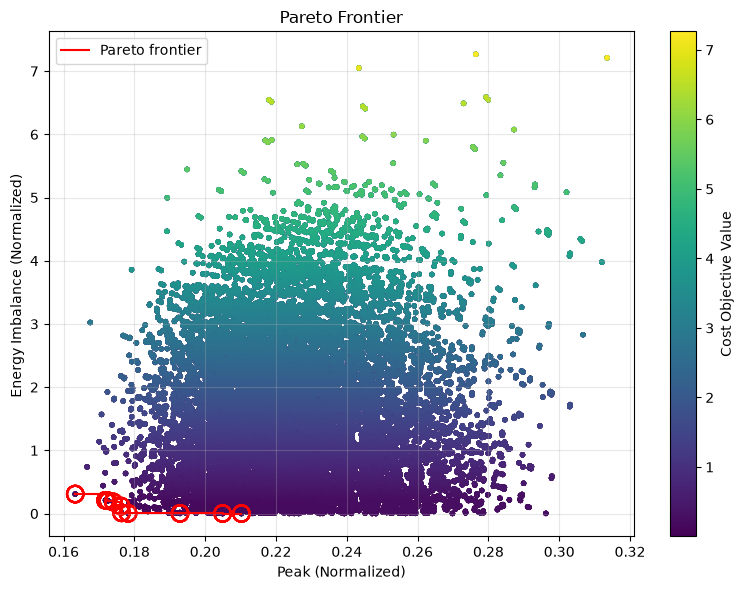

In [14]:
plot_pareto_fontier(
    building_loads=building_loads[:15],
    building_sizes=building_sizes[:15],
    seed_idx=0,
    k_min=5
)